In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,confusion_matrix,roc_auc_score,roc_curve
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

sns.set_theme(style='dark')

df = pd.read_csv(r"C:\Users\2024\Desktop\New folder\credit-risk-dataset-50k-loans-10-sectors-v3\loan_portfolio.csv")
df.head()

,loan_id,origination_date,maturity_date,maturity_months,sector,loan_type,collateral,initial_rating,credit_score,ead,...,pd_annual,lgd,el,unexpected_loss,rwa,defaulted,default_date,survival_months,recovery_rate,loss_given_default
0,L000001,2017-10-01,2019-10-01,24,Technology,mortgage,secured,B,704,1035611.99,...,0.041076,0.7858,33426.80,161508.03,442905.14,0,NaN,24,NaN,NaN
1,L000002,2016-06-01,2020-06-01,48,Healthcare,term_loan,unsecured,A,702,800786.92,...,0.000887,0.7034,499.82,16771.62,6622.66,0,NaN,48,NaN,NaN
2,L000003,2023-08-01,2024-12-31,36,Real_Estate,bond,secured,BBB,699,4327864.12,...,0.002622,0.5503,6243.54,121781.72,82726.94,0,NaN,36,NaN,NaN
3,L000004,2016-04-01,2024-12-31,120,Real_Estate,term_loan,secured,B,641,3810461.19,...,0.041679,0.3541,56237.33,269661.85,745144.64,0,NaN,120,NaN,NaN
4,L000005,2015-10-01,2019-10-01,48,Energy,bond,unsecured,CCC,597,2925538.53,...,0.136071,0.6576,261778.69,659614.05,3468567.58,0,NaN,48,NaN,NaN


In [3]:
target_column = 'defaulted'

columns_to_drop = [
    'default_date',
    'loan_id',
    'origination_date',
    'maturity_date',
    'maturity_months',
    'loan_type',
    'el',
    'unexpected_loss',
    'rwa',
    'pd_annual',
    'lgd',
    'recovery_rate',
    'survival_months',
    'loss_given_default'
]
    
for col in columns_to_drop:
    if col in df.columns:
        df = df.drop(columns=[col])
        
        
X = df.drop(columns=[target_column])
y = df[target_column]

X.head()
# print(df.columns.tolist())

,sector,collateral,initial_rating,credit_score,ead,coupon_rate,leverage,interest_coverage,debt_to_equity
0,Technology,secured,B,704,1035611.99,3.776,6.54,3.47,1.40
1,Healthcare,unsecured,A,702,800786.92,3.895,12.26,4.47,2.77
2,Real_Estate,secured,BBB,699,4327864.12,4.365,8.98,6.02,2.18
3,Real_Estate,secured,B,641,3810461.19,3.749,13.12,5.93,1.75
4,Energy,unsecured,CCC,597,2925538.53,5.231,1.80,4.39,1.79


In [4]:
for col in X.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    
X.head()    

C:\Users\2024\AppData\Local\Temp\ipykernel_23616\2629785652.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X.select_dtypes(include=['object']).columns:


,sector,collateral,initial_rating,credit_score,ead,coupon_rate,leverage,interest_coverage,debt_to_equity
0,7,1,3,704,1035611.99,3.776,6.54,3.47,1.40
1,3,2,0,702,800786.92,3.895,12.26,4.47,2.77
2,5,1,5,699,4327864.12,4.365,8.98,6.02,2.18
3,5,1,3,641,3810461.19,3.749,13.12,5.93,1.75
4,1,2,6,597,2925538.53,5.231,1.80,4.39,1.79


In [5]:
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(
    n_estimators=200, 
    max_depth=12, 
    min_samples_split=10,
    class_weight='balanced',
    random_state=42)

model.fit(X_train, y_train)

feature_imortance = pd.Series(
    model.feature_importances_, index=X.columns).sort_values(ascending=False)

print(feature_imortance.head())

initial_rating       0.369853
coupon_rate          0.185774
credit_score         0.161485
interest_coverage    0.063964
ead                  0.063867
dtype: float64


--- classifiction report ---
              precision    recall  f1-score   support

           0       0.91      0.85      0.88      8610
           1       0.35      0.48      0.40      1390

    accuracy                           0.80     10000
   macro avg       0.63      0.67      0.64     10000
weighted avg       0.83      0.80      0.81     10000

ROC_AUC score : 0.7535


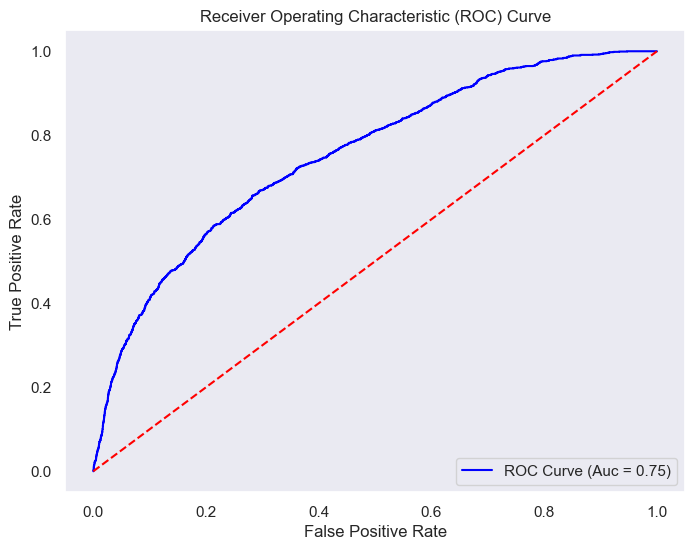

In [6]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print('--- classifiction report ---')
print(classification_report(y_test, y_pred))

print(f'ROC_AUC score : {roc_auc_score(y_test, y_prob):.4f}')

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(8, 6))
plt.plot(
    fpr,
    tpr,
    color='blue',
    label=f'ROC Curve (Auc = {roc_auc_score(y_test, y_prob):.2f})',
)
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.savefig('roc_curve.png')
plt.show()